# Assignment 1 — Data Exploration and Cleaning: External URLs

Each row represents a post–external-URL association. We examine structure, missing values, duplicates, consistency, outliers, and opportunities for integration and derived information.

Requirements: Python 3.10+, pandas 2.0+, NumPy, and Matplotlib. Adjust the paths below and run cells in order. Original files remain unchanged. `EXPORT = True` writes compressed CSVs; it is off by default to avoid creating large data copies.


In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import xml.etree.ElementTree as ET
import json
import re
import html
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"C:\Users\bucco\Desktop\Laboratory of Data Science\project")
DATA_DIR = PROJECT_DIR / "Truth-Social-Analysis-and-Data-Warehousing---Decision-Support-Systems-" / "Project_Data"
ARFF_PATH = PROJECT_DIR / "code_project" / "data" / "Additional_Data" / "additional_truths.arff"
EXPORT = False


## Structure, missing values, and exact duplicates

Identifiers are loaded without floating-point conversion. Repeated URLs across different posts are legitimate associations, not duplicate records.


In [2]:
with (DATA_DIR / "external_urls.json").open(encoding="utf-8") as file:
    data = json.load(file, parse_int=str, parse_float=str)
df_raw = pd.DataFrame(data, dtype="string")
del data
original_columns = df_raw.columns.tolist()
print("Rows and columns:", df_raw.shape)
display(df_raw.head())
display(pd.DataFrame({"Missing": df_raw.isna().sum(), "Blank": [df_raw[c].str.strip().eq("").sum() for c in df_raw], "Distinct": df_raw.nunique()}))


Rows and columns: (252877, 4)


,id_ext_url,url,truth_id,url_id
0,1780,https://www.supremecourt.gov/opinions/21pdf/19-1392_6j37.pdf,3207,1780
1,1780,https://www.supremecourt.gov/opinions/21pdf/19-1392_6j37.pdf,41909,1780
2,1780,https://www.supremecourt.gov/opinions/21pdf/19-1392_6j37.pdf,80108,1780
3,1780,https://www.supremecourt.gov/opinions/21pdf/19-1392_6j37.pdf,251504,1780
4,1780,https://www.supremecourt.gov/opinions/21pdf/19-1392_6j37.pdf,272831,1780


,Missing,Blank,Distinct
id_ext_url,0,0,173944
url,0,0,173944
truth_id,0,0,247461
url_id,0,0,173944


In [3]:
removed_duplicates = int(df_raw.duplicated().sum())
df_clean = df_raw.drop_duplicates().reset_index(drop=True).copy()
for col in df_clean:
    df_clean[col] = df_clean[col].str.strip().replace("", pd.NA)
id_columns = ['id_ext_url', 'url_id', 'truth_id']
for col in id_columns:
    values = df_clean[col].str.replace(r"\.0+$", "", regex=True)
    assert values.str.fullmatch(r"\d+", na=False).all(), f"Inspect invalid {col} values."
    df_clean[col] = pd.to_numeric(values, errors="raise").astype("Int64")
    assert df_clean[col].gt(0).all()
print("Exact duplicate rows removed:", removed_duplicates)
features = pd.DataFrame({"row_id": np.arange(len(df_clean))})


Exact duplicate rows removed: 5


In [4]:
features["identifier_mismatch"] = df_clean["id_ext_url"].ne(df_clean["url_id"])
features["id_has_multiple_urls"] = df_clean["url_id"].map(df_clean.groupby("url_id")["url"].nunique()).gt(1)
print("Repeated post–URL pairs:", df_clean.duplicated(["truth_id", "url_id"]).sum())
print("Identifier mismatches:", features["identifier_mismatch"].sum())
print("IDs with multiple URLs:", df_clean.groupby("url_id")["url"].nunique().gt(1).sum())
print("URL values assigned multiple IDs:", df_clean.groupby("url")["url_id"].nunique().gt(1).sum())


Repeated post–URL pairs: 0
Identifier mismatches: 0
IDs with multiple URLs: 0
URL values assigned multiple IDs: 0


## URL syntax and conservative cleaning

A syntactically valid URL need not be reachable or trustworthy. We do not visit websites, remove query parameters, lowercase paths, or invent a destination for bare usernames. Invalid values become missing in the clean URL field; their originals and associations are preserved for review.


In [5]:
def inspect_url(value):
    if pd.isna(value):
        return False, None, None, None
    try:
        parsed = urlsplit(value)
        port = parsed.port
        valid = bool(parsed.scheme.lower() in ["http", "https"] and parsed.hostname
                     and not any(c.isspace() for c in value)
                     and parsed.username is None and parsed.password is None)
        return valid, (parsed.hostname or "").lower().removeprefix("www.") or None, parsed.path, parsed.scheme.lower()
    except ValueError:
        return False, None, None, None


In [6]:
features["url_original"] = df_clean["url"]
parsed = pd.DataFrame(df_clean["url"].map(inspect_url).tolist(), columns=["valid_url", "hostname", "path", "scheme"])
features = pd.concat([features, parsed], axis=1)
features["url_length"] = df_clean["url"].str.len().astype("Int64")
features["has_query"] = df_clean["url"].str.contains("?", regex=False, na=False)
features["has_fragment"] = df_clean["url"].str.contains("#", regex=False, na=False)
df_clean.loc[~features["valid_url"], "url"] = pd.NA
print("Invalid URL associations retained:", (~features["valid_url"]).sum())
display(features.loc[~features["valid_url"], ["row_id", "url_original"]])


Invalid URL associations retained: 6


,row_id,url_original
131986,131986,gracechong
154698,154698,thomaswolfe
155195,155195,PatriotPlymouth2
155691,155691,TexanSeekingTruth
157697,157697,Moon52
185375,185375,DanMeyerswords


## Post references and recovery assessment

`truth_id` is checked as an internal main-corpus ID first, then against exact ARFF source IDs. A coincidental external-ID match is reported as a candidate, not used to rewrite the foreign key. Missing records in a partial corpus do not establish that the relationship is false.

The ARFF reference reader uses only the leading and trailing metadata fields of the supplied one-record-per-line file. It does not parse post text or claim to be a general ARFF reader.


In [7]:
needed_internal = set(df_clean["truth_id"].astype("string"))
needed_external = needed_internal.copy()


In [8]:
arff_rows = []
in_data = False
with ARFF_PATH.open(encoding="utf-8-sig") as file:
    for line in file:
        line = line.strip()
        if not in_data:
            in_data = line.lower() == "@data"
            continue
        if not line or line.startswith("%"):
            continue
        first = line.split(",", 2)
        tail = line.rsplit(",", 3)
        assert first[0].isdigit() and len(tail) == 4
        arff_rows.append((first[0], tail[1].strip("'\""), tail[2], first[1].strip("'\"")))
arff_ref = pd.DataFrame(arff_rows, columns=["source_id", "external_id", "author", "timestamp"], dtype="string")
del arff_rows
assert arff_ref["source_id"].is_unique
assert arff_ref["source_id"].eq(arff_ref["external_id"]).all()
arff_ref["author"] = pd.to_numeric(arff_ref["author"].str.replace(r"\.0+$", "", regex=True)).astype("Int64")
arff_ref["timestamp"] = pd.to_datetime(arff_ref["timestamp"], format="ISO8601", errors="raise")


In [9]:
main_ids, parts = set(), []
for chunk in pd.read_csv(DATA_DIR / "truths.csv", usecols=["id", "external_id", "url", "author", "timestamp"], dtype="string", keep_default_na=False, chunksize=100000):
    chunk["id"] = chunk["id"].str.replace(r"\.0+$", "", regex=True)
    assert chunk["id"].str.fullmatch(r"\d+", na=False).all()
    main_ids.update(chunk["id"])
    external = chunk["external_id"].where(chunk["external_id"].str.fullmatch(r"\d+", na=False))
    url_id = chunk["url"].str.extract(r"(?i)^https?://(?:www\.)?truthsocial\.com/@[^/?#]+/posts/(\d+)/?$", expand=False)
    url_id = url_id.combine_first(chunk["url"].where(chunk["url"].str.fullmatch(r"\d+", na=False)))
    mismatch = external.notna() & url_id.notna() & external.ne(url_id).fillna(False)
    chunk["external_id"] = external.combine_first(url_id).mask(mismatch)
    keep = chunk["id"].isin(needed_internal) | chunk["external_id"].isin(needed_external)
    parts.append(chunk.loc[keep, ["id", "external_id", "author", "timestamp"]].copy())
main_ref = pd.concat(parts, ignore_index=True).drop_duplicates()
del parts, chunk
main_ref["author"] = pd.to_numeric(main_ref["author"].str.replace(r"\.0+$", "", regex=True).replace("", pd.NA), errors="raise").astype("Int64")
main_ref["timestamp"] = pd.to_datetime(main_ref["timestamp"], format="ISO8601", errors="raise")
print("Distinct main-corpus IDs:", len(main_ids))


Distinct main-corpus IDs: 1038821


In [10]:
truth_keys = df_clean["truth_id"].astype("string")
features["post_reference_status"] = "missing"
features.loc[truth_keys.isin(main_ids), "post_reference_status"] = "main_internal"
arff_match = ~truth_keys.isin(main_ids) & truth_keys.isin(arff_ref["source_id"])
features.loc[arff_match, "post_reference_status"] = "arff_source_id"
external_candidate = ~truth_keys.isin(main_ids) & truth_keys.isin(main_ref["external_id"])
features["external_namespace_candidate"] = external_candidate
unresolved_post = features["post_reference_status"].eq("missing")
display(features["post_reference_status"].value_counts().to_frame("Relationships"))
print("Unresolved rows with an external-ID candidate:", (unresolved_post & external_candidate).sum())
display(df_clean.loc[unresolved_post].head(5))


Unresolved rows with an external-ID candidate: 0


,Relationships
post_reference_status,
main_internal,220699
missing,32173


,id_ext_url,url,truth_id,url_id
1,1780,https://www.supremecourt.gov/opinions/21pdf/19-1392_6j37.pdf,41909,1780
34,10,https://hannity.com/media-room/ben-on-the-mend-benjamin-hall-speaks-to-fox-news-family-6-months-after-attack-in-ukraine/,120,10
41,15,https://hannity.com/media-room/jimmy-eat-crow-kimmel-apologizes-for-dumb-emmys-stunt-actress-gets-payback-during-his-show/,125,15
58,26,https://hannity.com/media-room/constitutional-kari-lake-blasts-obama-we-cling-to-god-and-guns-to-protect-our-families/,136,26
59,26,https://hannity.com/media-room/constitutional-kari-lake-blasts-obama-we-cling-to-god-and-guns-to-protect-our-families/,494771,26


## Domains, repeated links, and outliers

Hostnames are lowercased with a leading `www.` removed. This is not a registered-domain classification. Domain counts describe link associations and distinct linked posts; they do not measure source reliability or political orientation.


,associations,urls,posts
hostname,,,
rumble.com,67263,40869,66300
thegatewaypundit.com,11036,5687,11018
justthenews.com,9839,4920,9837
foxsports.com,6669,6618,6669
breitbart.com,6244,3150,6243
gamespot.com,6054,6043,6054
t.me,5277,4760,5255
youtu.be,5007,4007,4984
hiphopdx.com,4880,4849,4880


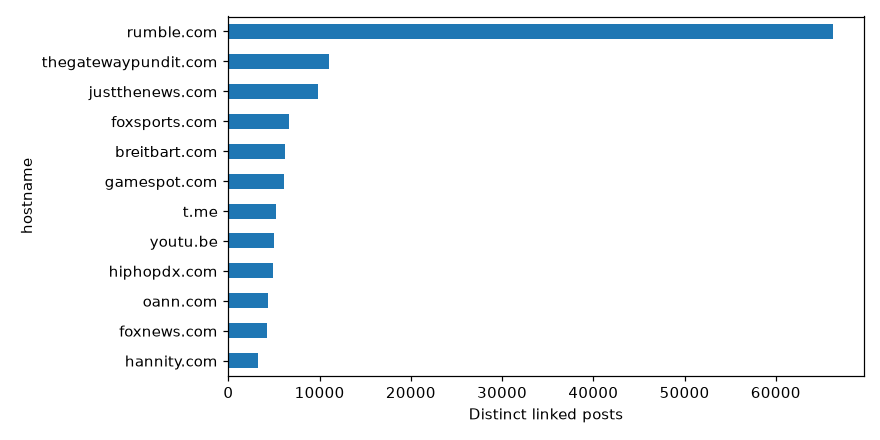

,URLs per linked post
count,247455.000000
mean,1.021867
std,0.167766
min,1.000000
50%,1.000000
90%,1.000000
95%,1.000000
99%,2.000000
max,9.000000


,Distinct valid URLs
truth_id,
700428,9
4495,8
748992,8
936671,8
114775,7
513361,7
276080,6
752441,6
13310,5


,Original URL length
count,252872.0
mean,85.412944
std,49.582378
min,6.0
50%,85.0
95%,174.0
99%,226.0
max,606.0


In [11]:
linked = df_clean.loc[features["valid_url"]].copy()
linked["hostname"] = features.loc[features["valid_url"], "hostname"]
domains = linked.groupby("hostname").agg(associations=("url_id", "size"), urls=("url_id", "nunique"), posts=("truth_id", "nunique")).sort_values("associations", ascending=False)
display(domains.head(15))
domains.head(12)["posts"].sort_values().plot.barh(figsize=(8, 4))
plt.xlabel("Distinct linked posts")
plt.tight_layout()
plt.show()
urls_per_post = linked.groupby("truth_id")["url_id"].nunique()
display(urls_per_post.describe(percentiles=[.5, .9, .95, .99]).to_frame("URLs per linked post"))
q1, q3 = urls_per_post.quantile([.25, .75])
high_posts = urls_per_post[urls_per_post > q3 + 1.5 * (q3 - q1)].index
features["many_urls_on_post"] = df_clean["truth_id"].isin(high_posts)
display(urls_per_post.nlargest(10).to_frame("Distinct valid URLs"))
display(features["url_length"].describe(percentiles=[.5, .95, .99]).to_frame("Original URL length"))


## Final validation and exports

We preserve the original column structure. Features retain `row_id`, the zero-based row position in the cleaned export. Unresolved links remain in the cleaned data and are also listed for review.


In [12]:
df_final = df_clean[original_columns].copy()
assert len(df_final) == len(df_raw) - removed_duplicates
assert df_final[id_columns].notna().all().all()
assert df_final[id_columns].gt(0).all().all()
assert len(features) == len(df_final)
assert features["row_id"].tolist() == list(range(len(df_final)))
review_mask = (
    unresolved_post
    | ~features["valid_url"]
    | features["identifier_mismatch"]
    | features["id_has_multiple_urls"]
)
issues = pd.concat([features.loc[review_mask], df_final.loc[review_mask]], axis=1)
quality_summary = pd.Series({
    "Original rows": len(df_raw), "Exact duplicates removed": removed_duplicates,
    "Cleaned rows": len(df_final), "Rows for review": int(review_mask.sum()),
    "Missing cells after cleaning": int(df_final.isna().sum().sum())
}, name="Count")
display(quality_summary.to_frame())


,Count
Original rows,252877
Exact duplicates removed,5
Cleaned rows,252872
Rows for review,32178
Missing cells after cleaning,6


In [13]:
OUTPUT_DIR = Path.cwd() / "output_external_urls"
if EXPORT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    df_final.to_csv(OUTPUT_DIR / "external_urls_clean.csv.gz", index=False, chunksize=50000)
    features.to_csv(OUTPUT_DIR / "external_urls_features.csv.gz", index=False, chunksize=50000)
    issues.to_csv(OUTPUT_DIR / "external_urls_issues.csv.gz", index=False)
    quality_summary.to_csv(OUTPUT_DIR / "external_urls_quality_summary.csv", index_label="Check")
    print("Exported to:", OUTPUT_DIR.resolve())
else:
    print("Analysis and cleaning complete. Set EXPORT = True to save datasets.")


Analysis and cleaning complete. Set EXPORT = True to save datasets.


## Conclusions and Assignment 1 coverage

**Observed results:** Original rows: 252,877; Exact duplicates removed: 5; Cleaned rows: 252,872; Rows for review: 32,178; Missing cells after cleaning: 6.

Valid URL associations support domain and sharing analyses. Bare usernames cannot establish an external destination, so their rows are retained with missing cleaned URLs and original-value audit fields. Orphan post references and format conflicts are documented; no new posts or locations are invented. High per-post URL counts and long URLs are retained, not classified as spam. This dataset has no timestamp or free post text for reliable temporal or place extraction.

This notebook covers structure and types, missing values, duplicates and mappings, data-specific anomalies, outliers, post/user integrity where applicable, recovery assessments, derived features, and validated cleaning. Only supplied files are used. The full ARFF-to-Truths integration is implemented in `04_additional_truths_complete.ipynb`; this notebook's reference checks do not replace it.

Compressed CSVs are readable directly with `pd.read_csv(path)`. Original invalid values and unresolved cases remain traceable in features or issue tables. The sources are the supplied dataset, related original datasets, the Assignment 1 instructions, and its original exploration/cleaning notebooks.
